# Pandas — Labelled data for scientific computing

Pandas extends NumPy with labelled arrays and tabular data. It supports inspection, selection, cleaning, aggregation, and file exchange.

This tutorial follows the progression of the accompanying Python, NumPy, Matplotlib, and SciPy notebooks: a short explanation, a small example, and an exercise. The examples use synthetic laboratory measurements with explicit units. They are not experimental observations.

Execute the cells from top to bottom. All data are created locally; no downloads or auxiliary files are required. The CSV examples write only to a temporary directory. Prerequisites: basic Python, NumPy arrays, and elementary plotting.

## Contents

1. Setup and labelled data
2. DataFrame construction and inspection
3. Indexing, selection, and alignment
4. Vectorised calculations and data cleaning
5. Grouping, joining, and reshaping
6. Time series and plotting
7. CSV input/output and NumPy interoperability
8. Exercises and worked solutions

## Setup — run this first

Use the conventional alias `pd`. NumPy supplies numerical arrays; Matplotlib supplies the plotting interface.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from io import StringIO
from pathlib import Path
from tempfile import TemporaryDirectory

pd.set_option('display.max_rows', 12)
pd.set_option('display.max_columns', 10)
plt.rcParams.update({'figure.figsize': (8, 4), 'font.size': 11})
rng = np.random.default_rng(42)
print('Pandas:', pd.__version__)

Pandas: 2.2.3


## Why labelled data?

A NumPy array stores values efficiently. A Pandas `Series` also records the label associated with each value. Labels reduce ambiguity when measurements are reordered.

In [2]:
voltages = np.array([10.1, 15.1, 9.5])
currents = np.array([1.2, 2.4, 5.2])
voltages / currents

array([8.41666667, 6.29166667, 1.82692308])

In [3]:
voltage = pd.Series(voltages, index=['run_A', 'run_B', 'run_C'], name='voltage_V')
voltage

run_A    10.1
run_B    15.1
run_C     9.5
Name: voltage_V, dtype: float64

## Series: values, index, and type

A Series has one data type and one index. Its labels need not be integers.

In [4]:
voltage.index

Index(['run_A', 'run_B', 'run_C'], dtype='object')

In [5]:
voltage.dtype

dtype('float64')

In [6]:
voltage.loc['run_B']

np.float64(15.1)

In [7]:
voltage.iloc[1]

np.float64(15.1)

## Automatic alignment

Arithmetic aligns Series by label, rather than by position. An unmatched label produces a missing result.

In [8]:
current = pd.Series([5.2, 1.2, 2.4], index=['run_C', 'run_A', 'run_B'], name='current_A')
voltage / current

run_A    8.416667
run_B    6.291667
run_C    1.826923
dtype: float64

In [9]:
other = pd.Series([1.0, 2.0], index=['run_A', 'run_D'])
voltage + other

run_A    11.1
run_B     NaN
run_C     NaN
run_D     NaN
dtype: float64

The first calculation pairs the correct runs despite their different order. In the second, only `run_A` appears in both Series. Label alignment is useful, but it must be intentional.

## Creating a DataFrame

A `DataFrame` is a table whose columns may have different data types. Here each row represents one measurement.

In [10]:
df = pd.DataFrame({
    'run': np.arange(1, 13),
    'sensor': ['A', 'B', 'C'] * 4,
    'voltage_V': [1.0, 1.1, 1.2, 2.0, 2.1, 2.2, 3.0, 3.1, 3.2, 4.0, 4.1, 4.2],
    'current_A': [0.10, 0.11, 0.12, 0.20, 0.21, 0.22, 0.30, 0.31, 0.32, 0.40, 0.41, 0.42],
    'temperature_C': [20.1, 20.4, 20.0, 20.2, 20.6, 20.3, 20.7, 20.9, 20.5, 21.0, 21.2, 20.8],
})
df.head()

,run,sensor,voltage_V,current_A,temperature_C
0,1,A,1.0,0.10,20.1
1,2,B,1.1,0.11,20.4
2,3,C,1.2,0.12,20.0
3,4,A,2.0,0.20,20.2
4,5,B,2.1,0.21,20.6


In [11]:
df.tail(3)

,run,sensor,voltage_V,current_A,temperature_C
9,10,A,4.0,0.40,21.0
10,11,B,4.1,0.41,21.2
11,12,C,4.2,0.42,20.8


In [12]:
df.shape, df.columns.tolist()

((12, 5), ['run', 'sensor', 'voltage_V', 'current_A', 'temperature_C'])

In [13]:
df.dtypes

run                int64
sensor            object
voltage_V        float64
current_A        float64
temperature_C    float64
dtype: object

## Inspecting a table

Inspect the schema and summary before calculating derived quantities. Descriptive statistics do not establish whether a measurement is physically valid.

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   run            12 non-null     int64  
 1   sensor         12 non-null     object 
 2   voltage_V      12 non-null     float64
 3   current_A      12 non-null     float64
 4   temperature_C  12 non-null     float64
dtypes: float64(3), int64(1), object(1)
memory usage: 612.0+ bytes


In [15]:
df.describe()

,run,voltage_V,current_A,temperature_C
count,12.000000,12.000000,12.000000,12.000000
mean,6.500000,2.600000,0.260000,20.558333
std,3.605551,1.170858,0.117086,0.375278
min,1.000000,1.000000,0.100000,20.000000
25%,3.750000,1.800000,0.180000,20.275000
50%,6.500000,2.600000,0.260000,20.550000
75%,9.250000,3.400000,0.340000,20.825000
max,12.000000,4.200000,0.420000,21.200000


In [16]:
df['sensor'].value_counts()

sensor
A    4
B    4
C    4
Name: count, dtype: int64

## Selecting columns

A single column name returns a Series. A list of column names returns a DataFrame, even when the list contains one name.

In [17]:
df['voltage_V'].head()

0    1.0
1    1.1
2    1.2
3    2.0
4    2.1
Name: voltage_V, dtype: float64

In [18]:
df[['voltage_V', 'current_A']].head()

,voltage_V,current_A
0,1.0,0.10
1,1.1,0.11
2,1.2,0.12
3,2.0,0.20
4,2.1,0.21


In [19]:
type(df['voltage_V']), type(df[['voltage_V']])

(<class 'pandas.core.series.Series'>, <class 'pandas.core.frame.DataFrame'>)

## Selecting rows with loc and iloc

Use `.loc` for labels and `.iloc` for integer positions. Label slices include the final label; positional slices exclude the final position.

In [20]:
indexed = df.set_index('run')
indexed.loc[2:4, ['sensor', 'voltage_V']]

,sensor,voltage_V
run,,
2,B,1.1
3,C,1.2
4,A,2.0


In [21]:
indexed.iloc[1:4, :3]

,sensor,voltage_V,current_A
run,,,
2,B,1.1,0.11
3,C,1.2,0.12
4,A,2.0,0.20


In [22]:
indexed.at[3, 'voltage_V'], indexed.iat[2, 1]

(np.float64(1.2), np.float64(1.2))

## Exercise I: Selection and alignment

Select sensor B measurements with voltage at least 2 V. Return only the run, voltage, and current columns. Then explain why Series arithmetic may differ from positional NumPy arithmetic.

Try the task before consulting the worked solutions at the end.

In [23]:
# Build a Boolean mask and select the requested columns.
# selected = ...

## Boolean masks

Combine elementwise conditions with `&`, `|`, and `~`. Parentheses around each condition are required. Python `and` does not combine entire Boolean Series.

In [24]:
mask = (df['sensor'] == 'A') & (df['temperature_C'] > 20.2)
df.loc[mask]

,run,sensor,voltage_V,current_A,temperature_C
6,7,A,3.0,0.3,20.7
9,10,A,4.0,0.4,21.0


In [25]:
df.loc[df['sensor'].isin(['A', 'C'])].head()

,run,sensor,voltage_V,current_A,temperature_C
0,1,A,1.0,0.10,20.1
2,3,C,1.2,0.12,20.0
3,4,A,2.0,0.20,20.2
5,6,C,2.2,0.22,20.3
6,7,A,3.0,0.30,20.7


In [26]:
df.query('voltage_V >= 3 and sensor == "B"')

,run,sensor,voltage_V,current_A,temperature_C
7,8,B,3.1,0.31,20.9
10,11,B,4.1,0.41,21.2


## Vectorised calculations

Operations act on whole columns. For Ohm’s law, resistance is $R=U/I$. Check zero and missing currents before division.

In [27]:
valid_current = df['current_A'].where(df['current_A'] > 0)
df['resistance_ohm'] = df['voltage_V'] / valid_current
df['power_W'] = df['voltage_V'] * df['current_A']
df.head()

,run,sensor,voltage_V,current_A,temperature_C,resistance_ohm,power_W
0,1,A,1.0,0.10,20.1,10.0,0.100
1,2,B,1.1,0.11,20.4,10.0,0.121
2,3,C,1.2,0.12,20.0,10.0,0.144
3,4,A,2.0,0.20,20.2,10.0,0.400
4,5,B,2.1,0.21,20.6,10.0,0.441


In [28]:
df.assign(voltage_mV=1000 * df['voltage_V']).head()

,run,sensor,voltage_V,current_A,temperature_C,resistance_ohm,power_W,voltage_mV
0,1,A,1.0,0.10,20.1,10.0,0.100,1000.0
1,2,B,1.1,0.11,20.4,10.0,0.121,1100.0
2,3,C,1.2,0.12,20.0,10.0,0.144,1200.0
3,4,A,2.0,0.20,20.2,10.0,0.400,2000.0
4,5,B,2.1,0.21,20.6,10.0,0.441,2100.0


## Sorting and ranking

Sorting changes row order. It does not automatically replace the index.

In [29]:
df.sort_values(['sensor', 'voltage_V'], ascending=[True, False]).head()

,run,sensor,voltage_V,current_A,temperature_C,resistance_ohm,power_W
9,10,A,4.0,0.40,21.0,10.0,1.600
6,7,A,3.0,0.30,20.7,10.0,0.900
3,4,A,2.0,0.20,20.2,10.0,0.400
0,1,A,1.0,0.10,20.1,10.0,0.100
10,11,B,4.1,0.41,21.2,10.0,1.681


In [30]:
df.nlargest(3, 'power_W')[['run', 'power_W']]

,run,power_W
11,12,1.764
10,11,1.681
9,10,1.600


## Assignment and copies

Use a single `.loc` assignment when updating selected rows. Avoid chained assignment such as `df[mask][column] = value`. Make an explicit copy when creating an independent working table.

In [31]:
working = df.copy()
working.loc[working['sensor'] == 'A', 'temperature_C'] += 0.1
working.loc[working['sensor'] == 'A', ['run', 'temperature_C']]

,run,temperature_C
0,1,20.2
3,4,20.3
6,7,20.8
9,10,21.1


In [32]:
# The original table is unchanged.
df.loc[df['sensor'] == 'A', ['run', 'temperature_C']]

,run,temperature_C
0,1,20.1
3,4,20.2
6,7,20.7
9,10,21.0


## Missing values

Missing data are not equivalent to zero. Pandas provides `isna`, `dropna`, and `fillna`; the appropriate treatment depends on the measurement process.

In [33]:
dirty = df[['run', 'sensor', 'voltage_V', 'current_A']].copy()
dirty.loc[2, 'current_A'] = np.nan
dirty.loc[5, 'current_A'] = 0.0
dirty.loc[8, 'voltage_V'] = np.nan
dirty

,run,sensor,voltage_V,current_A
0,1,A,1.0,0.10
1,2,B,1.1,0.11
2,3,C,1.2,NaN
3,4,A,2.0,0.20
4,5,B,2.1,0.21
5,6,C,2.2,0.00
6,7,A,3.0,0.30
7,8,B,3.1,0.31
8,9,C,NaN,0.32
9,10,A,4.0,0.40


In [34]:
dirty.isna().sum()

run          0
sensor       0
voltage_V    1
current_A    1
dtype: int64

In [35]:
dirty.dropna(subset=['voltage_V', 'current_A'])

,run,sensor,voltage_V,current_A
0,1,A,1.0,0.10
1,2,B,1.1,0.11
3,4,A,2.0,0.20
4,5,B,2.1,0.21
5,6,C,2.2,0.00
6,7,A,3.0,0.30
7,8,B,3.1,0.31
9,10,A,4.0,0.40
10,11,B,4.1,0.41
11,12,C,4.2,0.42


In [36]:
# A numerical demonstration, not a default laboratory correction.
dirty['current_A'].fillna(dirty['current_A'].median())

0     0.10
1     0.11
2     0.30
3     0.20
4     0.21
5     0.00
6     0.30
7     0.31
8     0.32
9     0.40
10    0.41
11    0.42
Name: current_A, dtype: float64

Imputation changes the data and should be documented. For machine learning, estimate imputation values from the training data only. The scikit-learn notebook demonstrates this with a Pipeline.

## Exercise II: Quality control

Keep rows with finite voltage and strictly positive, finite current. Calculate resistance for the accepted rows. Report the number rejected; do not replace invalid currents by an arbitrary small number.

Try the task before consulting the worked solutions at the end.

In [37]:
# clean = dirty.loc[...].copy()
# clean['resistance_ohm'] = ...

## Nullable types

Use nullable integer types when integer observations may be missing. A missing integer is not an observation of zero.

In [38]:
counts = pd.Series([12, 15, None, 11], dtype='Int64', name='photon_count')
counts

0      12
1      15
2    <NA>
3      11
Name: photon_count, dtype: Int64

In [39]:
counts.isna(), counts.mean()

(0    False
1    False
2     True
3    False
Name: photon_count, dtype: bool, np.float64(12.666666666666666))

## Strings and categories

String methods operate on Series. Categories represent a finite set of labels and can make repeated labels more explicit.

In [40]:
names = pd.Series([' Sensor A ', 'sensor b', None], dtype='string')
names.str.strip().str.lower()

0    sensor a
1    sensor b
2        <NA>
dtype: string

In [41]:
categories = df['sensor'].astype('category')
categories.cat.categories

Index(['A', 'B', 'C'], dtype='object')

## Duplicates

Duplicate rows may represent repeated records or legitimate repeated measurements. Inspect them before removal.

In [42]:
duplicated = pd.concat([df, df.iloc[[0]]], ignore_index=True)
duplicated.loc[duplicated.duplicated(subset=['run'], keep=False)]

,run,sensor,voltage_V,current_A,temperature_C,resistance_ohm,power_W
0,1,A,1.0,0.1,20.1,10.0,0.1
12,1,A,1.0,0.1,20.1,10.0,0.1


In [43]:
deduplicated = duplicated.drop_duplicates(subset=['run'], keep='first')
len(duplicated), len(deduplicated)

(13, 12)

## Group by: split, apply, combine

`groupby` separates rows by a key and aggregates each subset. Here each sensor has four measurements.

In [44]:
df.groupby('sensor', observed=True)['temperature_C'].mean()

sensor
A    20.500
B    20.775
C    20.400
Name: temperature_C, dtype: float64

In [45]:
summary = df.groupby('sensor', observed=True).agg(
    n=('temperature_C', 'count'),
    mean_C=('temperature_C', 'mean'),
    std_C=('temperature_C', 'std'),
)
summary['sem_C'] = summary['std_C'] / np.sqrt(summary['n'])
summary

,n,mean_C,std_C,sem_C
sensor,,,,
A,4,20.500,0.424264,0.212132
B,4,20.775,0.350000,0.175000
C,4,20.400,0.336650,0.168325


Pandas `std()` uses the sample convention, `ddof=1`, by default. NumPy `std()` defaults to `ddof=0`. The standard error above assumes independent observations; systematic errors and temporal correlation require additional treatment.

## Transform: return one value per row

Aggregation returns one result per group. `transform` broadcasts a group result back to each original row.

In [46]:
df['temperature_offset_C'] = (df['temperature_C']
    - df.groupby('sensor', observed=True)['temperature_C'].transform('mean'))
df[['sensor', 'temperature_C', 'temperature_offset_C']].head(6)

,sensor,temperature_C,temperature_offset_C
0,A,20.1,-0.400
1,B,20.4,-0.375
2,C,20.0,-0.400
3,A,20.2,-0.300
4,B,20.6,-0.175
5,C,20.3,-0.100


## Exercise III: Sensor summaries

Calculate the count, mean, sample standard deviation, and standard error of temperature for each sensor. Which sensor has the highest mean? Explain the assumptions behind the standard error.

Try the task before consulting the worked solutions at the end.

In [47]:
# Use groupby and named aggregation.
# summary_exercise = ...

## Merging metadata

A merge associates measurements with a second table. Validate the expected relationship to prevent accidental row multiplication.

In [48]:
calibration = pd.DataFrame({'sensor': ['A', 'B', 'C'],
                            'gain': [1.01, 0.99, 1.00],
                            'location': ['bench_1', 'bench_2', 'bench_3']})
merged = df.merge(calibration, on='sensor', how='left', validate='many_to_one', indicator=True)
merged[['run', 'sensor', 'gain', '_merge']].head()

,run,sensor,gain,_merge
0,1,A,1.01,both
1,2,B,0.99,both
2,3,C,1.00,both
3,4,A,1.01,both
4,5,B,0.99,both


In [49]:
merged['voltage_corrected_V'] = merged['gain'] * merged['voltage_V']
assert len(merged) == len(df)
assert merged['_merge'].eq('both').all()
merged[['run', 'voltage_V', 'voltage_corrected_V']].head()

,run,voltage_V,voltage_corrected_V
0,1,1.0,1.010
1,2,1.1,1.089
2,3,1.2,1.200
3,4,2.0,2.020
4,5,2.1,2.079


## Concatenation

`concat` stacks compatible tables. It does not match rows by a relational key.

In [50]:
first = df.iloc[:6].copy()
second = df.iloc[6:].copy()
combined = pd.concat([first, second], ignore_index=True)
combined.shape

(12, 8)

## Wide and long formats

Long tables store observations in rows. Wide tables place selected categories in columns. `pivot` requires a unique value for each row–column pair; `pivot_table` can aggregate duplicates.

In [51]:
long = df[['run', 'sensor', 'voltage_V', 'current_A']].melt(
    id_vars=['run', 'sensor'], var_name='quantity', value_name='value')
long.head(6)

,run,sensor,quantity,value
0,1,A,voltage_V,1.0
1,2,B,voltage_V,1.1
2,3,C,voltage_V,1.2
3,4,A,voltage_V,2.0
4,5,B,voltage_V,2.1
5,6,C,voltage_V,2.2


In [52]:
wide = long.pivot(index=['run', 'sensor'], columns='quantity', values='value')
wide.head()

,quantity,current_A,voltage_V
run,sensor,,
1,A,0.10,1.0
2,B,0.11,1.1
3,C,0.12,1.2
4,A,0.20,2.0
5,B,0.21,2.1


In [53]:
df.pivot_table(index='sensor', values=['voltage_V', 'current_A'], aggfunc='mean', observed=True)

,current_A,voltage_V
sensor,,
A,0.25,2.5
B,0.26,2.6
C,0.27,2.7


## Exercise IV: Calibration and reshaping

Merge the calibration table, calculate corrected voltage, and report the mean corrected voltage per sensor. Reshape voltage and current into long format. Why must the units remain identifiable?

Try the task before consulting the worked solutions at the end.

In [54]:
# calibrated = ...
# long_exercise = ...

## Time series

A `DatetimeIndex` supports time-based slicing and resampling. The example contains one synthetic temperature observation per minute.

In [55]:
time_rng = np.random.default_rng(17)
time_index = pd.date_range('2025-01-01 09:00:00', periods=120, freq='min')
time_series = pd.Series(20 + 0.01*np.arange(120) + time_rng.normal(0, .12, 120),
                        index=time_index, name='temperature_C')
time_series.head()

2025-01-01 09:00:00    20.132151
2025-01-01 09:01:00    20.050612
2025-01-01 09:02:00    19.955203
2025-01-01 09:03:00    19.878771
2025-01-01 09:04:00    19.812645
Freq: min, Name: temperature_C, dtype: float64

In [56]:
time_series.loc['2025-01-01 09:10':'2025-01-01 09:15']

2025-01-01 09:10:00    19.826786
2025-01-01 09:11:00    20.221018
2025-01-01 09:12:00    19.876779
2025-01-01 09:13:00    20.353155
2025-01-01 09:14:00    20.210868
2025-01-01 09:15:00    20.093379
Freq: min, Name: temperature_C, dtype: float64

## Resampling and rolling windows

Resampling groups observations into time bins. A rolling window moves across the series. Both operations depend on the sampling convention.

In [57]:
ten_minute = time_series.resample('10min').mean()
ten_minute.head()

2025-01-01 09:00:00    19.994684
2025-01-01 09:10:00    20.154142
2025-01-01 09:20:00    20.200072
2025-01-01 09:30:00    20.340751
2025-01-01 09:40:00    20.387069
Freq: 10min, Name: temperature_C, dtype: float64

In [58]:
smoothed = time_series.rolling(window=5, min_periods=5).mean()
smoothed.head(7)

2025-01-01 09:00:00          NaN
2025-01-01 09:01:00          NaN
2025-01-01 09:02:00          NaN
2025-01-01 09:03:00          NaN
2025-01-01 09:04:00    19.965877
2025-01-01 09:05:00    19.949894
2025-01-01 09:06:00    19.932318
Freq: min, Name: temperature_C, dtype: float64

The five-observation window is trailing, so it uses the present and previous observations. Its first four values are missing. A centred window also uses future observations and is unsuitable for causal forecasting.

## Plotting with Pandas and Matplotlib

Pandas plotting methods return Matplotlib axes. Retain this object when adding units, legends, and annotations.

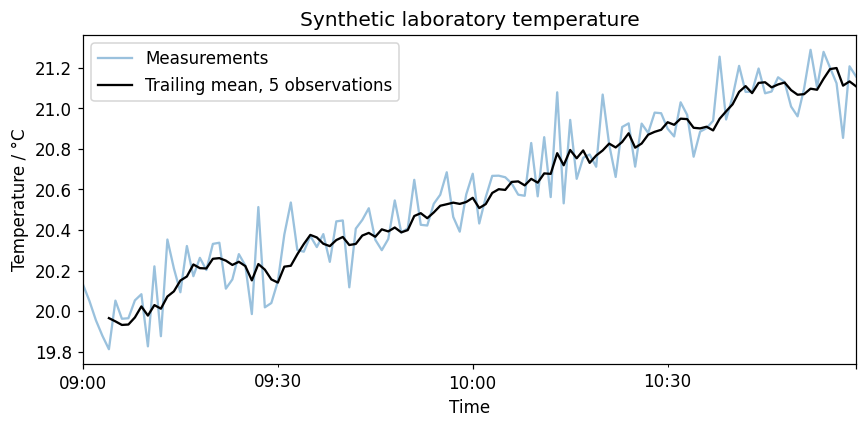

In [59]:
ax = time_series.plot(alpha=.45, label='Measurements')
smoothed.plot(ax=ax, color='black', label='Trailing mean, 5 observations')
ax.set(xlabel='Time', ylabel='Temperature / °C', title='Synthetic laboratory temperature')
ax.legend()
plt.tight_layout()
plt.show()

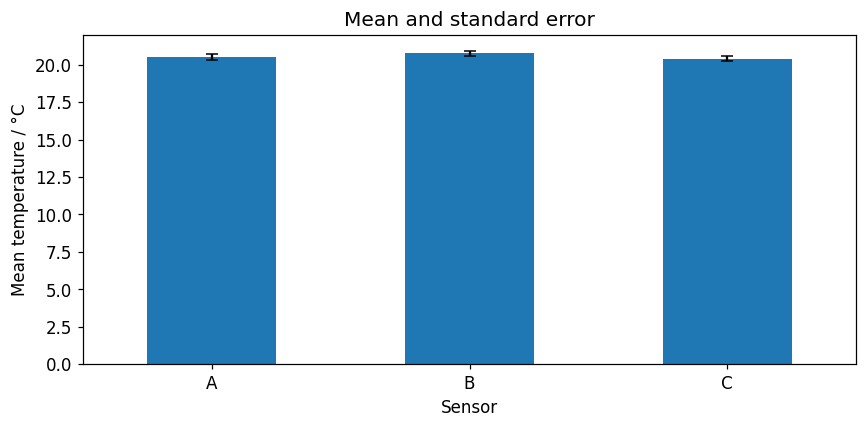

In [60]:
ax = summary['mean_C'].plot.bar(yerr=summary['sem_C'], capsize=4, rot=0)
ax.set(xlabel='Sensor', ylabel='Mean temperature / °C', title='Mean and standard error')
plt.tight_layout()
plt.show()

## Exercise V: Time aggregation

Calculate 15-minute means and counts. Plot the means and identify any incomplete bins. Explain why smoothing does not create additional independent measurements.

Try the task before consulting the worked solutions at the end.

In [61]:
# fifteen_minute = ...
# Plot means and inspect counts.

## Reading CSV text

A CSV file stores values and column names, but does not reliably preserve the complete schema. Inspect inferred types and specify missing-value markers when necessary.

In [62]:
csv_text = "sensor,voltage_V,current_A\nA,2.0,0.20\nB,3.0,missing\nC,4.0,0.40\n"
loaded = pd.read_csv(StringIO(csv_text), na_values=['missing'])
loaded

,sensor,voltage_V,current_A
0,A,2.0,0.2
1,B,3.0,NaN
2,C,4.0,0.4


In [63]:
loaded.dtypes

sensor        object
voltage_V    float64
current_A    float64
dtype: object

## Writing and reading a local file

Use `index=False` when the index is not part of the scientific data. A temporary directory keeps this demonstration self-contained.

In [64]:
with TemporaryDirectory() as folder:
    csv_path = Path(folder) / 'measurements.csv'
    df.to_csv(csv_path, index=False)
    restored = pd.read_csv(csv_path)
    print(csv_path.name, restored.shape)
    pd.testing.assert_frame_equal(df, restored, check_dtype=False, atol=1e-12, rtol=1e-12)
print('CSV round trip verified.')

measurements.csv (12, 8)
CSV round trip verified.


## NumPy interoperability

Select numerical columns before conversion. `to_numpy` discards labels and may coerce mixed column types.

In [65]:
measurement_array = df[['voltage_V', 'current_A']].to_numpy()
measurement_array.shape, measurement_array.dtype

((12, 2), dtype('float64'))

In [66]:
np.mean(measurement_array, axis=0)

array([2.6 , 0.26])

## Exercise VI: A complete analysis

Starting from `dirty`, reject invalid measurements, join calibration metadata, calculate corrected resistance, and return one mean per sensor. Verify that the merge does not change the accepted row count.

Try the task before consulting the worked solutions at the end.

In [67]:
# Combine quality control, merge, calculation, and aggregation.
# analysis = ...

## Common mistakes

Check label alignment before arithmetic. Use `.loc` for assignment. Distinguish missing observations from zero. Validate joins and retain units when reshaping. Prefer vectorised calculations to row loops when the operation is elementwise.

# Worked solutions

These examples are intended for comparison after an independent attempt. Each solution creates its own working variables and leaves the tutorial data unchanged.

## Solution I: Selection and alignment

In [68]:
mask_solution = (df['sensor'] == 'B') & (df['voltage_V'] >= 2)
selected_solution = df.loc[mask_solution, ['run', 'voltage_V', 'current_A']]
display(selected_solution)
assert selected_solution['run'].tolist() == [5, 8, 11]
# Series align labels; NumPy pairs array entries by their positions.

,run,voltage_V,current_A
4,5,2.1,0.21
7,8,3.1,0.31
10,11,4.1,0.41


## Solution II: Quality control

In [69]:
accepted = (np.isfinite(dirty['voltage_V']) & np.isfinite(dirty['current_A'])
            & (dirty['current_A'] > 0))
clean_solution = dirty.loc[accepted].copy()
clean_solution['resistance_ohm'] = clean_solution['voltage_V'] / clean_solution['current_A']
print('Rejected:', int((~accepted).sum()))
display(clean_solution)
assert len(clean_solution) == 9
assert np.allclose(clean_solution['resistance_ohm'], 10)

Rejected: 3


,run,sensor,voltage_V,current_A,resistance_ohm
0,1,A,1.0,0.10,10.0
1,2,B,1.1,0.11,10.0
3,4,A,2.0,0.20,10.0
4,5,B,2.1,0.21,10.0
6,7,A,3.0,0.30,10.0
7,8,B,3.1,0.31,10.0
9,10,A,4.0,0.40,10.0
10,11,B,4.1,0.41,10.0
11,12,C,4.2,0.42,10.0


## Solution III: Sensor summaries

In [70]:
summary_solution = df.groupby('sensor', observed=True).agg(
    n=('temperature_C', 'count'), mean=('temperature_C', 'mean'),
    std=('temperature_C', 'std'))
summary_solution['sem'] = summary_solution['std'] / np.sqrt(summary_solution['n'])
display(summary_solution)
print('Highest mean:', summary_solution['mean'].idxmax())
# The SEM formula requires independent observations; it excludes systematic uncertainty.

Highest mean: B


,n,mean,std,sem
sensor,,,,
A,4,20.500,0.424264,0.212132
B,4,20.775,0.350000,0.175000
C,4,20.400,0.336650,0.168325


## Solution IV: Calibration and reshaping

In [71]:
calibrated_solution = df.merge(calibration, on='sensor', validate='many_to_one')
calibrated_solution['voltage_corrected_V'] = calibrated_solution['voltage_V'] * calibrated_solution['gain']
display(calibrated_solution.groupby('sensor', observed=True)['voltage_corrected_V'].mean())
long_solution = calibrated_solution.melt(id_vars=['run','sensor'],
    value_vars=['voltage_V','current_A'], var_name='quantity', value_name='value')
display(long_solution.head())
# The value column mixes quantities; the quantity label retains their identity and units.

sensor
A    2.525
B    2.574
C    2.700
Name: voltage_corrected_V, dtype: float64

,run,sensor,quantity,value
0,1,A,voltage_V,1.0
1,2,B,voltage_V,1.1
2,3,C,voltage_V,1.2
3,4,A,voltage_V,2.0
4,5,B,voltage_V,2.1


## Solution V: Time aggregation

,mean,count
2025-01-01 09:00:00,20.029029,15
2025-01-01 09:15:00,20.203569,15
2025-01-01 09:30:00,20.355736,15
2025-01-01 09:45:00,20.470970,15
2025-01-01 10:00:00,20.657428,15
2025-01-01 10:15:00,20.845797,15
2025-01-01 10:30:00,21.004403,15
2025-01-01 10:45:00,21.114080,15


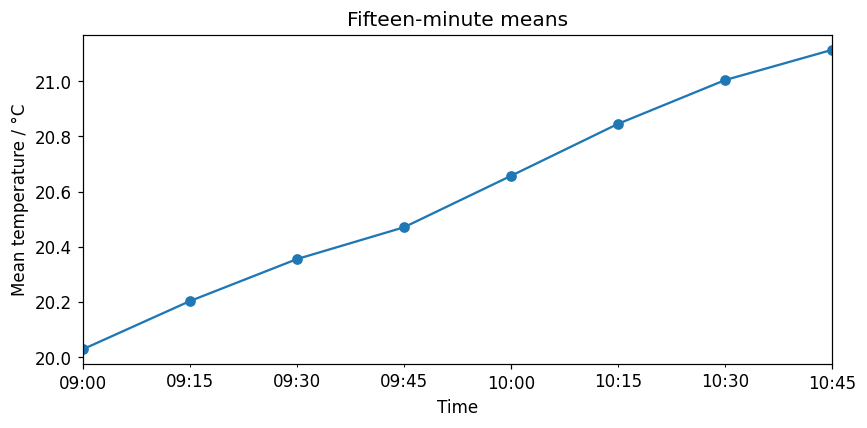

In [72]:
resampled_solution = time_series.resample('15min').agg(['mean', 'count'])
display(resampled_solution)
ax = resampled_solution['mean'].plot(marker='o')
ax.set(xlabel='Time', ylabel='Mean temperature / °C', title='Fifteen-minute means')
plt.tight_layout(); plt.show()
assert resampled_solution['count'].eq(15).all()
# All bins are complete here. Overlapping averages share observations.

## Solution VI: A complete analysis

In [73]:
ok_solution = (np.isfinite(dirty['voltage_V']) & np.isfinite(dirty['current_A'])
               & (dirty['current_A'] > 0))
analysis_solution = dirty.loc[ok_solution].merge(calibration, on='sensor', validate='many_to_one')
analysis_solution['corrected_resistance_ohm'] = (
    analysis_solution['voltage_V'] * analysis_solution['gain'] / analysis_solution['current_A'])
assert len(analysis_solution) == int(ok_solution.sum())
display(analysis_solution.groupby('sensor', observed=True)['corrected_resistance_ohm'].agg(['count','mean']))

,count,mean
sensor,,
A,4,10.1
B,4,9.9
C,1,10.0


# Documentation

- [Pandas introductory tutorial](https://pandas.pydata.org/docs/user_guide/10min.html)
- [Indexing and selection](https://pandas.pydata.org/docs/user_guide/indexing.html)
- [Grouping](https://pandas.pydata.org/docs/user_guide/groupby.html)
- [Missing data](https://pandas.pydata.org/docs/user_guide/missing_data.html)

These are original teaching examples, structured to accompany the four supplied introductory notebooks.